**Author:**

Kumar Jayant

# All Customers Are Equal, But Some Are More Equal Than Others: RFM, Step by Step

Companion notebook to the aimldl.io post (Part 1: end customers).

**Data:** UCI Online Retail II (Chen, 2012, CC BY 4.0), merged 2009–2011 file on Kaggle: `krjynt/online-retail-ii-2009-2011-merged`.

**What this notebook does**
1. Prepares the data (12-month window, non-product rows, end customers only, cancellations).
2. Computes Recency, Frequency and Monetary, and scores each 1–5.
3. Approach 1: ranks the 125 RFM cells (Hughes) and groups them into 11 named segments, with an action per segment.
4. Approach 2: three composite scores (simple sum, business-set weights, AHP), each cut into five tiers with an action per tier.
5. Profiles segments and tiers, draws the charts, and validates the scores against what customers did next.

> **Placeholders to set before publishing** (cell 2): the wholesaler rule, the business-set weights and the AHP judgments.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import KBinsDiscretizer
import glob, os
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Settings

Change parameters here

* **Window:** exactly 12 months ending on the snapshot date (10 Dec 2010 – 9 Dec 2011). For your own data, use a rolling 12 months for most retail and longer windows for long-cycle categories.
* **Wholesaler rule (PLACEHOLDER):** the dataset has no customer-type field. A customer is treated as a wholesaler if their median quantity per order line is above 12, or their average order value is above £1,000.
* **Business-set weights (PLACEHOLDER):** R 0.40, F 0.35, M 0.25 for a gift-ware seller.
* **AHP judgments (PLACEHOLDER):** R vs F = 1, R vs M = 3, F vs M = 2.

In [5]:
# Data: pulled straight from Kaggle (works in Colab and in Kaggle notebooks; cached after the first download).
# To run on your own file instead, comment out the next two lines and set DATA_PATH to your CSV, e.g.
# DATA_PATH = '/content/my_transactions.csv'

path = kagglehub.dataset_download('krjynt/online-retail-ii-2009-2011-merged')
DATA_PATH = glob.glob(os.path.join(path, '*.csv'))[0]
print(DATA_PATH)

100%|██████████| 14.2M/14.2M [00:00<00:00, 63.3MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/krjynt/online-retail-ii-2009-2011-merged/versions/1/merged_dataset_retail_2009_2011.csv


In [6]:
# DATA_PATH = 'merged_dataset_retail_2009_2011.csv'   # Colab: upload the file; Kaggle: '/kaggle/input/online-retail-ii-2009-2011-merged/...'

WINDOW_START = pd.Timestamp('2010-12-10')
WINDOW_END   = pd.Timestamp('2011-12-10')            # exclusive: data runs to 9 Dec 2011
SNAPSHOT     = WINDOW_END                            # 'today' for Recency = last day + 1

# PLACEHOLDER: wholesaler rule
WHOLESALE_MEDIAN_QTY = 12      # median quantity per order line above this = wholesaler
WHOLESALE_AOV        = 1000    # average order value (GBP) above this = wholesaler

# PLACEHOLDER: business-set weights for a gift-ware seller
BUSINESS_WEIGHTS = {'R': 0.40, 'F': 0.35, 'M': 0.25}

# PLACEHOLDER: AHP pairwise judgments (Saaty 1-9 scale): row vs column
AHP_MATRIX = np.array([[1,   1,   3],    # R vs R, F, M
                       [1,   1,   2],    # F
                       [1/3, 1/2, 1]])   # M

NON_PRODUCT_CODES = ['POST', 'DOT', 'M', 'm', 'C2', 'D', 'S', 'B', 'BANK CHARGES', 'AMAZONFEE',
                     'ADJUST', 'ADJUST2', 'PADS', 'CRUK', 'TEST001', 'TEST002']

## 2. Load the data

In [7]:
raw = pd.read_csv(DATA_PATH, dtype={'Invoice': str, 'StockCode': str})
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], format='mixed')
print(f'{len(raw):,} rows | {raw.InvoiceDate.min():%d %b %Y} to {raw.InvoiceDate.max():%d %b %Y}')
raw.head()

1,067,371 rows | 01 Dec 2009 to 09 Dec 2011


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 3. Prepare the data

Coding checklist, in order:
1. Dates are already converted above.
2. Drop exact duplicate rows, then rows with no Customer ID.
3. Keep only the 12-month window.
4. Remove non-product rows (postage, manual adjustments, bank charges, Amazon fees, discounts, gift vouchers, tests).
5. Keep end customers only; exclude wholesalers.
6. Handle cancellations: they don't count towards Frequency, and returned amounts are subtracted from Monetary.

In [8]:
steps = [('Raw rows', len(raw))]

df = raw.drop_duplicates()
steps.append(('Exact duplicate rows dropped', len(df)))

df = df.dropna(subset=['Customer ID']).copy()
df['Customer ID'] = df['Customer ID'].astype(int)
steps.append(('With a Customer ID', len(df)))

df = df[(df.InvoiceDate >= WINDOW_START) & (df.InvoiceDate < WINDOW_END)]
steps.append(('In the 12-month window', len(df)))

is_non_product = df.StockCode.isin(NON_PRODUCT_CODES) | df.StockCode.str.startswith('gift_0001')
print('Non-product rows removed:', df.loc[is_non_product, 'StockCode'].value_counts().to_dict())
df = df[~is_non_product]
steps.append(('Product rows only', len(df)))

df['Revenue'] = df.Quantity * df.Price
is_cancel = df.Invoice.str.startswith('C')
purchases = df[~is_cancel & (df.Quantity > 0) & (df.Price > 0)]          # real purchases
returns   = df[is_cancel & (df.Quantity < 0) & (df.Price > 0)]           # cancellations / returns
print(f'Other rows dropped (non-C rows with quantity <= 0 or price <= 0): {len(df) - len(purchases) - len(returns):,}')
pd.DataFrame(steps, columns=['Step', 'Rows'])

Non-product rows removed: {'POST': 1161, 'M': 441, 'C2': 129, 'D': 73, 'CRUK': 16, 'DOT': 16, 'BANK CHARGES': 11, 'PADS': 4}
Other rows dropped (non-C rows with quantity <= 0 or price <= 0): 32


,Step,Rows
0,Raw rows,1067371
1,Exact duplicate rows dropped,1033036
2,With a Customer ID,797885
3,In the 12-month window,387122
4,Product rows only,385271


### 3.1 End customers only

The dataset has no field that says who is a wholesaler, so we use a rule on each customer's purchases (see Settings). State the rule you use.

In [9]:
cust = (purchases.groupby('Customer ID')
                 .agg(median_qty=('Quantity', 'median'),
                      orders=('Invoice', 'nunique'),
                      spend=('Revenue', 'sum')))
cust['aov'] = cust.spend / cust.orders
cust['wholesaler'] = (cust.median_qty > WHOLESALE_MEDIAN_QTY) | (cust.aov > WHOLESALE_AOV)

end_customers = cust.index[~cust.wholesaler]
print(f'Customers who bought in the window: {len(cust):,}')
print(f'Wholesalers excluded: {cust.wholesaler.sum():,} ({cust.wholesaler.mean():.0%})')
print(f'End customers kept: {len(end_customers):,}')

purchases = purchases[purchases['Customer ID'].isin(end_customers)]
returns   = returns[returns['Customer ID'].isin(end_customers)]

Customers who bought in the window: 4,261
Wholesalers excluded: 655 (15%)
End customers kept: 3,606


## 4. Compute R, F and M

* **Recency:** days from the customer's last purchase to the snapshot date (10 Dec 2011). Never 0: a last-day buyer scores 1.
* **Frequency:** distinct purchase invoices (baskets), not order lines. Cancellations don't count.
* **Monetary:** net spend = purchases minus returns.

In [10]:
def compute_rfm(purchases, returns, snapshot):
    rfm = (purchases.groupby('Customer ID')
                    .agg(Recency=('InvoiceDate', lambda d: (snapshot - d.max().normalize()).days),
                         Frequency=('Invoice', 'nunique'),
                         Gross=('Revenue', 'sum')))
    returned = returns.groupby('Customer ID')['Revenue'].sum()          # negative values
    rfm['Returned'] = returned.reindex(rfm.index).fillna(0)
    rfm['Monetary'] = rfm.Gross + rfm.Returned                          # net spend
    return rfm

rfm = compute_rfm(purchases, returns, SNAPSHOT)
print(f'{len(rfm):,} end customers | net spend £{rfm.Monetary.sum():,.0f} | returns £{-rfm.Returned.sum():,.0f}')
rfm[['Recency', 'Frequency', 'Monetary']].describe(percentiles=[.25, .5, .75, .9])

3,606 end customers | net spend £4,774,438 | returns £102,981


,Recency,Frequency,Monetary
count,"3,606.00","3,606.00","3,606.00"
mean,87.36,4.06,"1,324.03"
std,94.09,7.13,"3,155.91"
min,1.00,1.00,"-1,573.65"
25%,18.00,1.00,291.16
50%,47.00,2.00,614.70
75%,131.75,5.00,"1,433.22"
90%,249.00,8.00,"2,968.05"
max,365.00,190.00,"124,506.66"


## 5. Score each 1–5

* **R:** fixed day cut-offs: 1–30 days = 5, 31–60 = 4, 61–90 = 3, 91–180 = 2, 181+ = 1.
* **F:** fixed order counts: 1 = 1, 2 = 2, 3 = 3, 4–5 = 4, 6+ = 5. (Quintiles fail on ties, and ranking breaks ties arbitrarily.)
* **M:** five natural bands found by 1-D KMeans on log spend. Negative net spend is clipped to 0 before the log, so it scores 1.

> **Keep the M bands fixed between runs.** The bands move every time you re-run. Next quarter's data gives new centroids, so a customer's M can change even when their spending didn't. Fit the bands once and reuse them with `kb.transform(...)`.

In [11]:
def score_rfm(rfm, kb=None):
    out = rfm.copy()
    out['R'] = pd.cut(out['Recency'], bins=[0, 30, 60, 90, 180, float('inf')], labels=[5, 4, 3, 2, 1]).astype(int)
    out['F'] = pd.cut(out['Frequency'], bins=[0, 1, 2, 3, 5, float('inf')], labels=[1, 2, 3, 4, 5]).astype(int)
    log_m = np.log1p(out[['Monetary']].clip(lower=0))
    if kb is None:                                   # first run: fit the bands
        kb = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='kmeans')
        kb.fit(log_m)
    out['M'] = kb.transform(log_m).ravel().astype(int) + 1
    return out, kb

rfm, kb = score_rfm(rfm)
m_edges = np.expm1(kb.bin_edges_[0])
print('M band edges (GBP):', ' | '.join(f'£{e:,.0f}' for e in m_edges))
for col in ['R', 'F', 'M']:
    print(col, rfm[col].value_counts().sort_index().to_dict())

M band edges (GBP): £0 | £27 | £257 | £730 | £2,212 | £124,507
R {1: 665, 2: 477, 3: 420, 4: 639, 5: 1405}
F {1: 1234, 2: 688, 3: 435, 4: 554, 5: 695}
M {1: 22, 2: 771, 3: 1225, 4: 1031, 5: 557}


## 6. Approach 1: 125 cells, ranked and named

**Step A — Hughes ranking.** Join the three scores into a cell code (555 … 111). The code is the rank: R first, then F, then M. With campaign data you would measure each cell's response rate and contact only cells above breakeven (cost per contact ÷ profit per response). This dataset has no campaign data, so we show the ranking and the sizes.

In [12]:
rfm['RFM_cell'] = rfm.R.astype(str) + rfm.F.astype(str) + rfm.M.astype(str)
cells = (rfm.groupby('RFM_cell')
            .agg(customers=('Monetary', 'size'), revenue=('Monetary', 'sum'))
            .sort_index(ascending=False))                      # 555 first ... 111 last
print(f'{len(cells)} of 125 cells have customers; {(cells.customers < 5).sum()} hold fewer than 5')
cells.head(10)

93 of 125 cells have customers; 30 hold fewer than 5


,customers,revenue
RFM_cell,,
555,363,"2,143,840.70"
554,163,"257,290.08"
553,7,"3,843.87"
552,1,191.17
545,44,"128,477.92"
544,197,"260,911.05"
543,43,"24,810.11"
542,1,220.10
535,4,"10,426.18"


**Step B — named segments.** The names are later marketing practice, not Hughes. Rules are checked top to bottom; the first match wins. Every one of the 125 cells lands in exactly one segment.

In [13]:
def segment(r, f, m):
    if r >= 4 and f >= 4: return 'Champions'
    if r >= 4 and f >= 2: return 'Potential loyalists'
    if r == 5:            return 'New customers'
    if r == 4:            return 'Promising'
    if r == 3 and f >= 4: return 'Loyal'
    if r == 3 and f >= 2: return 'Needs attention'
    if r == 3:            return 'About to sleep'
    if f >= 4 and m >= 4: return "Can't lose them"
    if f >= 3:            return 'At risk'
    if r == 2:            return 'Hibernating'
    return 'Lost'

SEGMENT_ORDER = ['Champions', 'Potential loyalists', 'New customers', 'Promising', 'Loyal', 'Needs attention',
                 'About to sleep', "Can't lose them", 'At risk', 'Hibernating', 'Lost']
SEGMENT_ACTION = {
    'Champions': 'Reward and recognise: early access, referral asks; no discounts',
    'Potential loyalists': 'Loyalty offer; cross-sell what similar baskets buy',
    'New customers': 'Onboarding; nudge the second purchase',
    'Promising': 'Small incentive for a second order',
    'Loyal': 'Keep engaged; ask for reviews; check why orders are slowing',
    'Needs attention': 'Time-limited offer built on past purchases',
    'About to sleep': 'Reactivate with popular products',
    "Can't lose them": 'Personal outreach; find out why they stopped',
    'At risk': 'Personalised win-back before they lapse fully',
    'Hibernating': 'Low-cost automated reactivation',
    'Lost': 'One last attempt, then stop spending on them',
}
rfm['Segment'] = [segment(r, f, m) for r, f, m in zip(rfm.R, rfm.F, rfm.M)]
rfm['Segment'] = pd.Categorical(rfm['Segment'], categories=SEGMENT_ORDER, ordered=True)

## 7. Approach 2: one composite score, three ways

Same five tiers for every method. Weighted scores stay on the 1–5 scale because the weights add up to 1; their cut-offs are the simple-sum cut-offs divided by 3.

**AHP:** turn the pairwise judgments into weights (normalise each column, average each row) and check the consistency ratio (below 0.10 is acceptable).

In [14]:
ahp_w = (AHP_MATRIX / AHP_MATRIX.sum(axis=0)).mean(axis=1)
lam = (AHP_MATRIX @ ahp_w / ahp_w).mean()
CR = ((lam - 3) / 2) / 0.58                 # 0.58 = Saaty's random index for 3 factors
print('AHP weights  R {:.2f} | F {:.2f} | M {:.2f}'.format(*ahp_w), f'| consistency ratio {CR:.3f}')

TIERS = ['Dormant', 'Low', 'Medium', 'High', 'Top']
TIER_ACTION = {
    'Top': 'Protect and reward: priority stock, account manager, early access, referrals; no discounts',
    'High': 'Grow: loyalty offer, cross-sell based on similar baskets',
    'Medium': 'Targeted offers on past purchases; reorder reminders timed to their cycle',
    'Low': 'Low-cost automated reactivation',
    'Dormant': 'One last attempt, then stop spending on them',
}
X = rfm[['R', 'F', 'M']].astype(int)
weights = {'Biz': [BUSINESS_WEIGHTS['R'], BUSINESS_WEIGHTS['F'], BUSINESS_WEIGHTS['M']], 'AHP': list(ahp_w.round(2))}

rfm['Sum_score'] = X.sum(axis=1)
rfm['Sum_tier'] = pd.cut(rfm['Sum_score'], bins=[3, 5, 7, 10, 13, 16], labels=TIERS, right=False)
for name, w in weights.items():
    rfm[name + '_score'] = (X @ w).round(2)
    rfm[name + '_tier'] = pd.cut(rfm[name + '_score'], bins=[1, 1.67, 2.33, 3.33, 4.33, 5.01], labels=TIERS, right=False)

pd.DataFrame({m: rfm[m + '_tier'].value_counts().reindex(TIERS[::-1]) for m in ['Sum', 'Biz', 'AHP']})

AHP weights  R 0.44 | F 0.39 | M 0.17 | consistency ratio 0.016


,Sum,Biz,AHP
Top,912,878,879
High,834,745,737
Medium,1010,904,902
Low,566,470,467
Dormant,284,609,621


## 8. Profile: share of customers vs share of revenue

For each segment and tier: customers, share of customers, share of net revenue, and average R, F, M.

In [15]:
def profile(by):
    p = (rfm.groupby(by, observed=True)
            .agg(customers=('Monetary', 'size'), revenue=('Monetary', 'sum'),
                 avg_recency_days=('Recency', 'mean'), avg_frequency=('Frequency', 'mean'), avg_spend=('Monetary', 'mean')))
    p['pct_customers'] = 100 * p.customers / p.customers.sum()
    p['pct_revenue'] = 100 * p.revenue / p.revenue.sum()
    return p[['customers', 'pct_customers', 'pct_revenue', 'avg_recency_days', 'avg_frequency', 'avg_spend']]

seg_profile = profile('Segment')
seg_profile['action'] = [SEGMENT_ACTION[s] for s in seg_profile.index]
seg_profile

,customers,pct_customers,pct_revenue,avg_recency_days,avg_frequency,avg_spend,action
Segment,,,,,,,
Champions,1046,29.01,69.54,18.85,9.21,"3,174.00","Reward and recognise: early access, referral a..."
Potential loyalists,613,17.00,9.19,25.71,2.43,715.79,Loyalty offer; cross-sell what similar baskets...
New customers,189,5.24,1.06,17.78,1.00,267.06,Onboarding; nudge the second purchase
Promising,196,5.44,1.22,44.78,1.00,297.01,Small incentive for a second order
Loyal,102,2.83,3.94,73.64,5.65,"1,842.43",Keep engaged; ask for reviews; check why order...
Needs attention,149,4.13,2.40,73.59,2.38,768.54,Time-limited offer built on past purchases
About to sleep,169,4.69,1.19,73.01,1.00,337.17,Reactivate with popular products
Can't lose them,70,1.94,2.47,138.86,5.11,"1,683.71",Personal outreach; find out why they stopped
At risk,145,4.02,2.28,160.10,3.38,751.02,Personalised win-back before they lapse fully


In [16]:
tier_profiles = {m: profile(m + '_tier').reindex(TIERS[::-1]) for m in ['Sum', 'Biz', 'AHP']}
pd.concat(tier_profiles, names=['Method'])[['customers', 'pct_customers', 'pct_revenue']]

customers  pct_customers  pct_revenue
Method Sum_tier                                       
Sum    Top             912          25.29        67.52
       High            834          23.13        17.79
       Medium         1010          28.01        10.11
       Low             566          15.70         3.74
       Dormant         284           7.88         0.84
Biz    Top             878          24.35        65.26
       High            745          20.66        16.91
       Medium          904          25.07        10.66
       Low             470          13.03         4.33
       Dormant         609          16.89         2.84
AHP    Top             879          24.38        65.26
       High            737          20.44        16.48
       Medium          902          25.01        10.87
       Low             467          12.95         4.34
       Dormant         621          17.22         3.04

### Score vs segment: where the two approaches disagree

A composite tells you how much a customer is worth overall, not why. The cross-table below shows where Approach 1's segments land in the business-set tiers. Look at "Can't lose them": a high-value customer gone quiet rarely reaches the Top tier.

In [17]:
pd.crosstab(rfm.Segment, rfm.Biz_tier).reindex(columns=TIERS[::-1])

Biz_tier,Top,High,Medium,Low,Dormant
Segment,,,,,
Champions,878,168,0,0,0
Potential loyalists,0,450,163,0,0
New customers,0,3,186,0,0
Promising,0,0,193,3,0
Loyal,0,101,1,0,0
Needs attention,0,3,146,0,0
About to sleep,0,0,13,156,0
Can't lose them,0,20,50,0,0
At risk,0,0,119,26,0


## 9. Charts

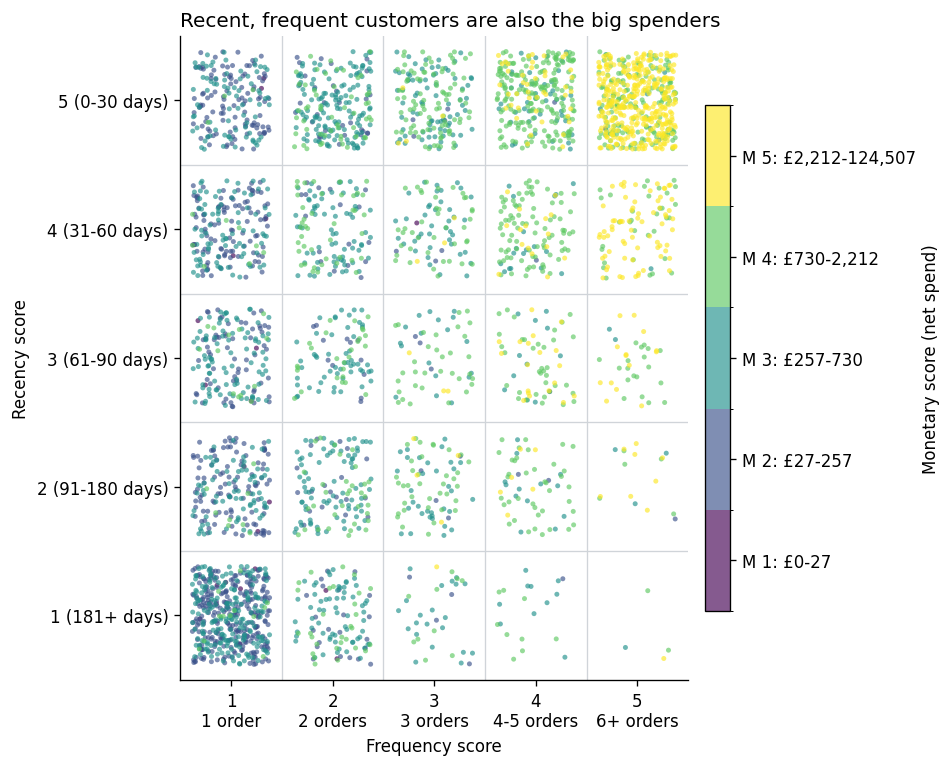

In [24]:
# Jitter each customer inside their R x F cell so the points form a cloud instead of stacking on one spot
rng = np.random.default_rng(42)
R = rfm['R'].astype(int).to_numpy()
F = rfm['F'].astype(int).to_numpy()
M = rfm['M'].astype(int).to_numpy()
x = F + rng.uniform(-0.38, 0.38, len(rfm))
y = R + rng.uniform(-0.38, 0.38, len(rfm))

order = np.argsort(M, kind='stable')             # draw low M first, so high-M customers sit on top
cmap = plt.get_cmap('viridis', 5)                # one colour per M score
norm = BoundaryNorm(np.arange(0.5, 6.5), cmap.N)

fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(x[order], y[order], c=M[order], cmap=cmap, norm=norm, s=9, alpha=0.65, linewidths=0)

# Thin lines between cells, so the 25 R x F cells stay readable
for v in np.arange(1.5, 5.5):
    ax.axvline(v, color='#d0d4d9', lw=0.8, zorder=0)
    ax.axhline(v, color='#d0d4d9', lw=0.8, zorder=0)

ax.set_xticks(range(1, 6), ['1\n1 order', '2\n2 orders', '3\n3 orders', '4\n4-5 orders', '5\n6+ orders'])
ax.set_yticks(range(1, 6), ['1 (181+ days)', '2 (91-180 days)', '3 (61-90 days)', '4 (31-60 days)', '5 (0-30 days)'])
ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5)
ax.set_xlabel('Frequency score'); ax.set_ylabel('Recency score')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

# Colour bar labelled with the M bands in pounds (m_edges comes from the scoring cell)
cbar = fig.colorbar(sc, ax=ax, ticks=range(1, 6), fraction=0.046, pad=0.03)
cbar.ax.set_yticklabels([f'M {i}: £{m_edges[i-1]:,.0f}-{m_edges[i]:,.0f}' for i in range(1, 6)])
cbar.set_label('Monetary score (net spend)')

ax.set_title('Recent, frequent customers are also the big spenders', loc='left')
fig.tight_layout()
fig.savefig('charts/rfm_cloud.png', dpi=200)
plt.show()

**How to read this chart**

Every dot is one customer. Up the side is Recency: the higher the row, the more recently they bought. Across the bottom is Frequency: the further right, the more orders they placed. The colour is Monetary: purple and blue are small spenders, and green and yellow are big spenders, from £27 at the bottom of the scale to over £2,212 at the top.

The 25 boxes are the R×F cells. Inside a box, a dot’s exact position means nothing; the dots are just spread out so you can see how many there are. What matters is which box a dot sits in, and its colour.

**What it shows**

The top-right box is almost all yellow. Customers who bought in the last 30 days and placed six or more orders are also the biggest spenders. These are the Champions: the three footprints line up.
The bottom-left box is the densest cloud on the chart, mostly purple and blue. It’s full of customers who bought once, more than six months ago, and spent little. They’re the largest group, and the least valuable.
The yellow fades as you move down any column. The same order count is worth less as Recency drops, because frequent customers who stop coming stop spending.
The bottom-right corner is nearly empty, but not quite. The few green and yellow dots there are big, frequent spenders who have gone quiet: the “Can’t lose them” customers. They’re easy to miss in a revenue report, and they’re the ones worth a phone call.

**The takeaway**

Value isn’t spread evenly across your customer list. It sits in one corner, and it leaks out of that corner one quiet customer at a time. Watch the top-right box to protect what you have, and the bottom-right to catch what you’re about to lose.

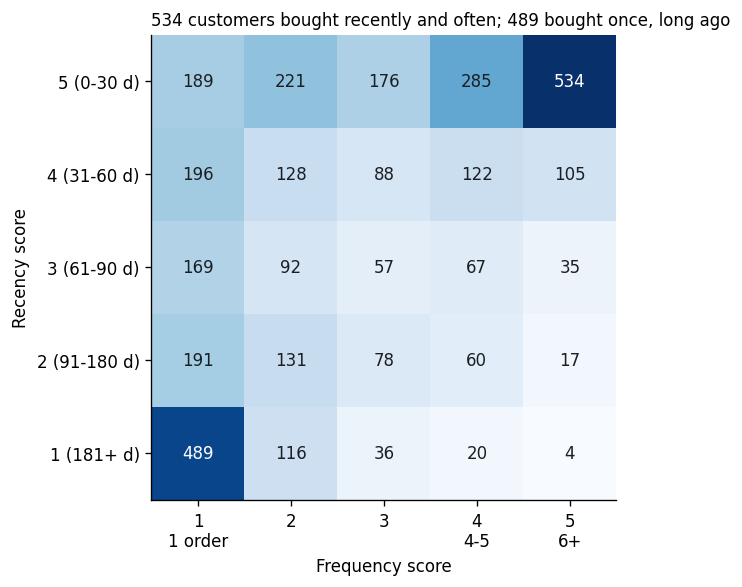

In [26]:
os.makedirs('charts', exist_ok=True)
GREY, ACCENT = '#9aa0a6', '#1f6feb'

# 1. R x F heatmap: customers in each cell
heat = pd.crosstab(rfm.R, rfm.F).reindex(index=[5, 4, 3, 2, 1], columns=[1, 2, 3, 4, 5], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat.values, cmap='Blues')
for i in range(5):
    for j in range(5):
        v = heat.values[i, j]
        ax.text(j, i, f'{v:,}', ha='center', va='center', color='white' if v > heat.values.max() * 0.55 else '#1b1f24', fontsize=10)
ax.set_xticks(range(5), ['1\n1 order', '2', '3', '4\n4-5', '5\n6+'])
ax.set_yticks(range(5), ['5 (0-30 d)', '4 (31-60 d)', '3 (61-90 d)', '2 (91-180 d)', '1 (181+ d)'])
ax.set_xlabel('Frequency score'); ax.set_ylabel('Recency score')
ax.set_title(f'{heat.loc[5, 5]:,} customers bought recently and often; {heat.loc[1, 1]:,} bought once, long ago', loc='left', fontsize=10)
fig.tight_layout(); fig.savefig('charts/rf_heatmap.png', dpi=200); plt.show()

**How to read this chart**

Each box counts how many customers share the same Recency and Frequency score. Up the side is Recency: the top row bought in the last 30 days, and the bottom row more than six months ago. Across the bottom is Frequency: one order on the left, six or more on the right. The darker the box, the more customers in it.

**What it shows**

The two darkest boxes sit in opposite corners. Top right: 534 customers bought in the last 30 days and placed six or more orders. That’s 15% of the base, and they’re your Champions. Bottom left: 489 customers bought once, more than six months ago. That’s 14% of the base, and most of them are lost.
One order is the most common story. The left column holds 1,234 customers, a third of the base, who have bought only once. It’s the biggest group in every row except the top one. Getting a second order is the first job of any retention plan.
The top row is busy, partly because of the season. 39% of customers bought in the last 30 days. The data ends on 9 December, in the Christmas rush, so a snapshot taken in June would look quieter. That’s why you compare a run with the same month last year, not with last month.
Frequency without Recency thins out fast. Move down the right-hand column and the counts drop from 534 to 105, 35, 17 and 4. Frequent buyers rarely go quiet. The few who do (the 101 customers in the bottom-right four boxes) deserve attention before they join the 489.

**The takeaway**

Most of the customer base sits at the two ends: a loyal core that keeps coming back, and a long tail that bought once and never returned. The work is in the middle: turning one order into two, and catching frequent buyers the moment they slow down.

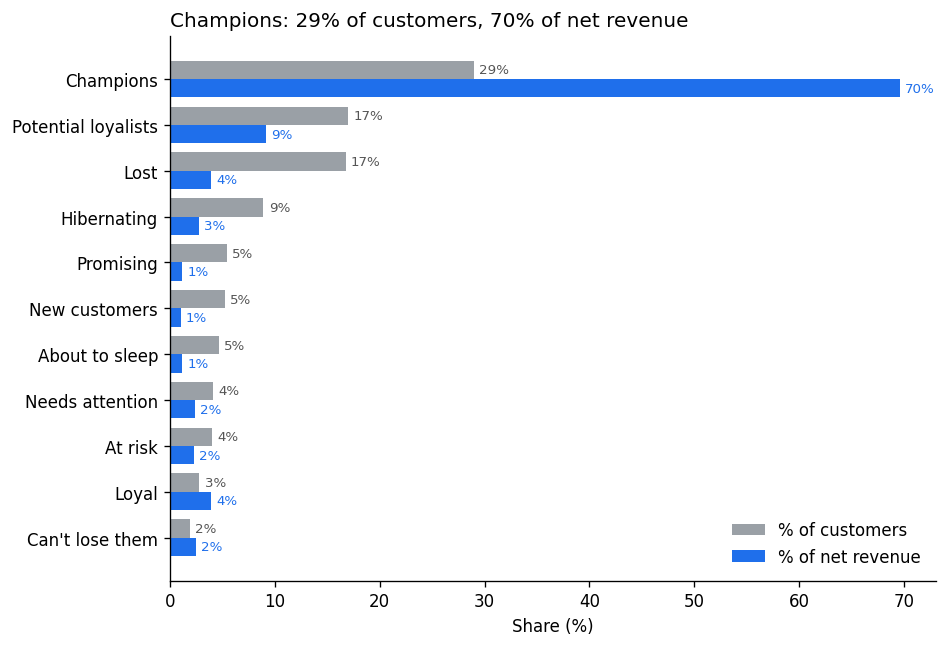

In [19]:
# 2. Segment sizes: share of customers vs share of revenue
sp = seg_profile.sort_values('pct_customers')
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(sp))
ax.barh(y + 0.2, sp.pct_customers, height=0.4, color=GREY, label='% of customers')
ax.barh(y - 0.2, sp.pct_revenue, height=0.4, color=ACCENT, label='% of net revenue')
for yi, c, r in zip(y, sp.pct_customers, sp.pct_revenue):
    ax.text(c + 0.5, yi + 0.2, f'{c:.0f}%', va='center', fontsize=8, color='#555')
    ax.text(max(r, 0) + 0.5, yi - 0.2, f'{r:.0f}%', va='center', fontsize=8, color=ACCENT)
ax.set_yticks(y, sp.index); ax.set_xlabel('Share (%)')
ch = seg_profile.loc['Champions']
ax.set_title(f"Champions: {ch.pct_customers:.0f}% of customers, {ch.pct_revenue:.0f}% of net revenue", loc='left')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig('charts/segment_sizes.png', dpi=200); plt.show()

**How to read this chart**

Each segment has two bars. The grey bar shows its share of customers, and the blue bar its share of net revenue. When the blue bar is longer, the segment earns more than its headcount suggests. When the grey bar is longer, it’s a crowd that spends little.

**What it shows**

*   Champions carry the business. They are 29% of customers and bring 70% of net revenue, more than all the other segments combined. Losing a handful of them hurts more than losing hundreds of the rest.

*   Only two segments earn more than their headcount share. Champions (29% → 70%) and Loyal (3% → 4%) are the only ones where the blue bar beats the grey. Both buy often, so frequency is what turns a customer into revenue.
The biggest crowd brings the least. Lost and Hibernating together are 26% of customers but only 7% of revenue. Spending heavily to win them back rarely pays.
*   Potential loyalists are the growth pool. They are 17% of customers but only 9% of revenue. They’ve bought recently, two or three times. Moving even some of them into Champions would add more revenue than any win-back campaign.
*   “Can’t lose them” looks small, but the bars mislead. They are 2% of customers and 2% of revenue: about 70 people with the spending habits of a Champion, now gone quiet. That 2% is revenue walking out of the door, and a phone call costs little.

**The takeaway**

Protect the 29% who bring 70%. Grow the 17% next in line. Call the 2% who are slipping. Automate the rest, and stop spending on the 26% who have already gone.

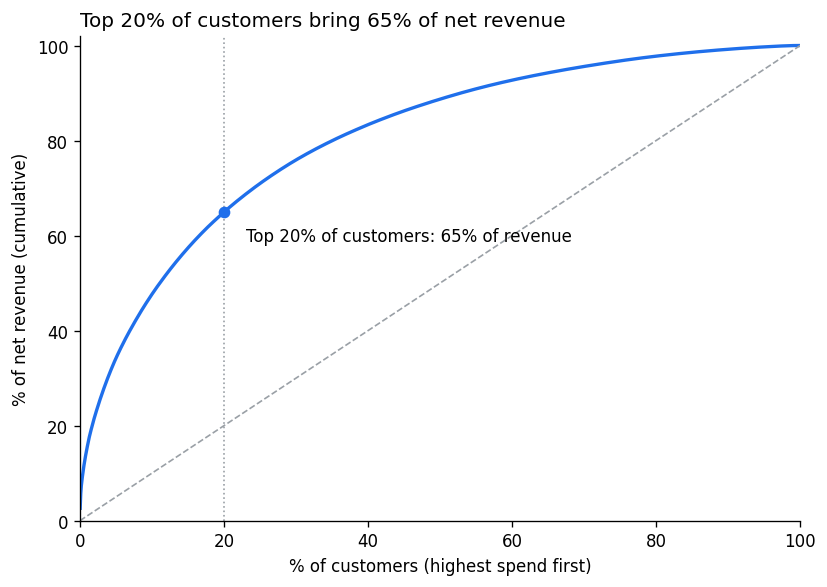

Top 20% of customers bring 64.9% of net revenue


In [20]:
# 3. Pareto: cumulative share of revenue by customers ranked on spend
s = rfm.Monetary.clip(lower=0).sort_values(ascending=False)
cum_rev = 100 * s.cumsum() / s.sum()
cum_cust = 100 * np.arange(1, len(s) + 1) / len(s)
top20 = cum_rev.iloc[int(len(s) * 0.2) - 1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cum_cust, cum_rev, color=ACCENT, lw=2)
ax.plot([0, 100], [0, 100], color=GREY, lw=1, ls='--')
ax.axvline(20, color=GREY, lw=1, ls=':')
ax.plot([20], [top20], 'o', color=ACCENT)
ax.text(23, top20 - 6, f'Top 20% of customers: {top20:.0f}% of revenue', fontsize=10)
ax.set_xlabel('% of customers (highest spend first)'); ax.set_ylabel('% of net revenue (cumulative)')
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title(f'Top 20% of customers bring {top20:.0f}% of net revenue', loc='left')
fig.tight_layout(); fig.savefig('charts/pareto.png', dpi=200); plt.show()
print(f'Top 20% of customers bring {top20:.1f}% of net revenue')

**How to read this chart**

Line up every customer from the biggest spender to the smallest. Moving left to right along the bottom, you add customers in that order, and the blue line shows what share of total revenue you’ve reached so far. The dashed grey diagonal is a world where every customer spends the same: 20% of customers would bring 20% of revenue. The further the blue line bows above the diagonal, the more revenue is concentrated in a few customers.

**What it shows**

The top 20% of customers bring 65% of net revenue. That’s the marked point. The well-known “80/20 rule” (named after the economist Vilfredo Pareto) is a rule of thumb, not a law. Here the split is closer to 20/65, still a heavy tilt towards a few customers.
The curve climbs steeply, then flattens. The top 40% bring about 85% of revenue. After that, each extra slice of customers adds very little.
The bottom half of the list brings only about 10% of revenue. Half of all customers, roughly a tenth of the money.

**Why it matters for RFM**

This chart ranks customers on spend alone, the M in RFM. It tells you how concentrated the revenue is, but not who is about to leave. A big spender who went quiet seven months ago still sits at the top of this curve. That’s why RFM adds Recency and Frequency: the Pareto chart shows where the money came from, and RFM shows where it’s likely to come from next.

**The takeaway**

Revenue is concentrated, so customer attention should be too. But concentration cuts both ways: losing a few customers at the top of this curve costs more than losing hundreds at the bottom.

### End of code